# 02 - Exploratory Data Analysis

Goal: Understand the Glassdoor reviews dataset before any modelling or data preparation.  
Sections: Basic overview → Target variable (`recommend`) → Numeric sub-ratings → Text features → Metadata → Data quality flags

All visualisations saved to `../figures/`.

In [142]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pointbiserialr
import seaborn as sns
import os

# Project utilities
import sys
sys.path.insert(0, "../src")
from utils import (
    save_fig, set_plot_style, backup_notebook,
    SEED, FIG_DIR, TARGET_COLORS, TARGET_ORDER, SEQUENTIAL_CMAP, RATING_LABELS
)

# Apply consistent styling
set_plot_style()
np.random.seed(SEED)

# # Load data
df = pd.read_csv("../data/glassdoor_reviews.csv")
print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")

print("Setup complete.")

Dataset loaded: 838,566 rows, 18 columns
Setup complete.


### Data Source & Context

This dataset contains **838,566 employee reviews** from Glassdoor, covering **2008–2021**, sourced from [Kaggle](https://www.kaggle.com/datasets/davidgauthier/glassdoor-job-reviews). Each row represents a single review left by a current or former employee.

**Key columns:**
- **Target:** `recommend` — whether the reviewer recommends the employer (3 classes: Positive, No Opinion, Negative)
- **Sub-ratings:** 6 numeric scores (1–5 scale) on aspects like work–life balance, culture, career opportunities, etc.
- **CEO & Outlook:** ceo_approv and outlook (Positive, Mild, Negative, No Opinion) 
- **Text:** `headline`, `pros`, and `cons` — free-text fields written by the reviewer
- **Metadata:** firm name, job title, employee status (current/former + tenure), location, and review date

---
## 2.1 Basic Overview

Initial inspection of dataset shape, column types, sample rows, and duplicate detection.

In [98]:
# Shape and data types
print("Shape:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nFirst 5 rows:")
df.head()

Shape: (838566, 18)

Column types:
firm                       str
date_review                str
job_title                  str
current                    str
location                   str
overall_rating           int64
work_life_balance      float64
culture_values         float64
diversity_inclusion    float64
career_opp             float64
comp_benefits          float64
senior_mgmt            float64
recommend                  str
ceo_approv                 str
outlook                    str
headline                   str
pros                       str
cons                       str
dtype: object

First 5 rows:


,firm,date_review,job_title,current,location,overall_rating,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt,recommend,ceo_approv,outlook,headline,pros,cons
0,AFH-Wealth-Management,2015-04-05,,Current Employee,NaN,2,4.0,3.0,NaN,2.0,3.0,3.0,x,o,r,"Young colleagues, poor micro management",Very friendly and welcoming to new staff. Easy...,"Poor salaries, poor training and communication."
1,AFH-Wealth-Management,2015-12-11,Office Administrator,"Current Employee, more than 1 year","Bromsgrove, England, England",2,3.0,1.0,NaN,2.0,1.0,4.0,x,o,r,"Excellent staff, poor salary","Friendly, helpful and hard-working colleagues",Poor salary which doesn't improve much with pr...
2,AFH-Wealth-Management,2016-01-28,Office Administrator,"Current Employee, less than 1 year","Bromsgrove, England, England",1,1.0,1.0,NaN,1.0,1.0,1.0,x,o,x,"Low salary, bad micromanagement",Easy to get the job even without experience in...,"Very low salary, poor working conditions, very..."
3,AFH-Wealth-Management,2016-04-16,,Current Employee,NaN,5,2.0,3.0,NaN,2.0,2.0,3.0,x,o,r,Over promised under delivered,Nice staff to work with,No career progression and salary is poor
4,AFH-Wealth-Management,2016-04-23,Office Administrator,"Current Employee, more than 1 year","Bromsgrove, England, England",1,2.0,1.0,NaN,2.0,1.0,1.0,x,o,x,client reporting admin,"Easy to get the job, Nice colleagues.","Abysmal pay, around minimum wage. No actual tr..."


In [99]:
# Duplicate rows
n_dupes = df.duplicated().sum()
print(f"Duplicate rows: {n_dupes:,} ({n_dupes / len(df) * 100:.2f}%)")

# Inspect a sample of duplicates
if n_dupes > 0:
    dupes = df[df.duplicated(keep=False)].sort_values(list(df.columns))
    print("\nSample duplicate group:")
    display(dupes.head(4))

Duplicate rows: 33,515 (4.00%)

Sample duplicate group:


,firm,date_review,job_title,current,location,overall_rating,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt,recommend,ceo_approv,outlook,headline,pros,cons
1231,ASDA,2010-10-29,Asda Manager,Former Employee,NaN,5,5.0,NaN,NaN,5.0,5.0,4.0,v,o,o,bil,"great team work, working together",long hours long shift patterns
1232,ASDA,2010-10-29,Asda Manager,Former Employee,NaN,5,5.0,NaN,NaN,5.0,5.0,4.0,v,o,o,bil,"great team work, working together",long hours long shift patterns
1271,ASDA,2013-04-24,Shop Floor Assistant,"Current Employee, more than 1 year",NaN,4,2.0,4.0,NaN,3.0,4.0,3.0,v,v,v,"Good company to work for, very customer experi...",10% discount on shopping in store and online\r...,Always short staffed with huge targets to hit\...
1272,ASDA,2013-04-24,Shop Floor Assistant,"Current Employee, more than 1 year",NaN,4,2.0,4.0,NaN,3.0,4.0,3.0,v,v,v,"Good company to work for, very customer experi...",10% discount on shopping in store and online\r...,Always short staffed with huge targets to hit\...


**Takeaway — Basic Overview:**
- **838,566 rows** and **18 columns** (7 numeric, 11 object/string).
- `diversity_inclusion` stands out with **83.8% missing** — likely structural (introduced later in the dataset timeline).
- **33,515 duplicate rows (4%)** — will be removed in data preparation.

---
## 2.2 Target Variable: `recommend`

Exploring the distribution of the target variable.

In [144]:
# Raw codes and mapping
print("Raw unique values:", df["recommend"].unique())
print("\nRaw value counts:")
print(df["recommend"].value_counts())

# Map codes to readable labels for exploration
# v = Positive, o = No Opinion, x = Negative
recommend_map = {"v": "Positive", "o": "No Opinion", "x": "Negative"}
df["recommend_label"] = df["recommend"].map(recommend_map)

rec_counts = df["recommend_label"].value_counts()
rec_pct = (rec_counts / len(df) * 100).round(1)
print("\nRecommend distribution:")
print(pd.DataFrame({"Count": rec_counts, "Percent": rec_pct}))

Raw unique values: <ArrowStringArray>
['x', 'o', 'v']
Length: 3, dtype: str

Raw value counts:
recommend
v    427865
o    234248
x    176453
Name: count, dtype: int64

Recommend distribution:
                  Count  Percent
recommend_label                 
Positive         427865     51.0
No Opinion       234248     27.9
Negative         176453     21.0


Saved: eda_target_distribution_v5.png


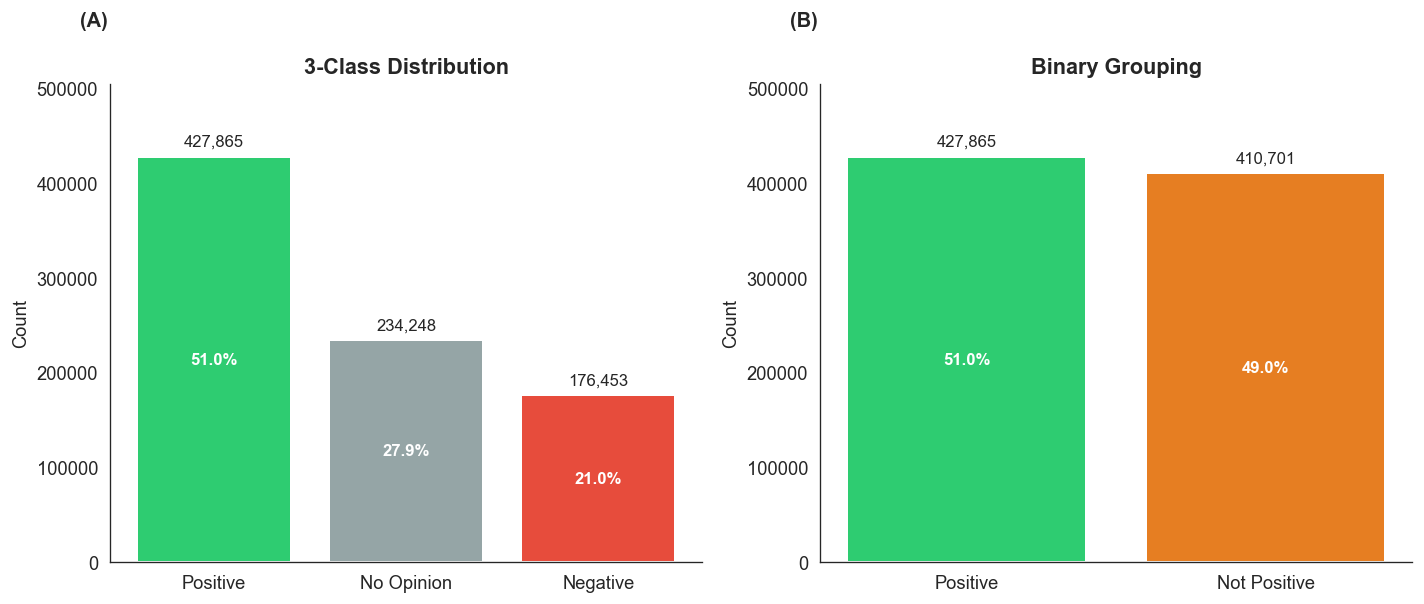

In [149]:
# --- VISUALISATION: Target distribution ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart: 3-class distribution
counts_ordered = df["recommend_label"].value_counts().reindex(TARGET_ORDER)
bars = axes[0].bar(TARGET_ORDER, counts_ordered, 
                   color=[TARGET_COLORS[x] for x in TARGET_ORDER], 
                   edgecolor="white", linewidth=1.2)
axes[0].set_title("3-Class Distribution")
axes[0].text(-0.05, 1.12, "(A)", transform=axes[0].transAxes, fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")
axes[0].set_xlabel("")
axes[0].set_ylim(0, counts_ordered.max() * 1.18)

for bar, count in zip(bars, counts_ordered):
    axes[0].annotate(f"{count:,}",
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8000),
                     ha="center", va="bottom", fontsize=10)
    axes[0].annotate(f"{count / len(df) * 100:.1f}%",
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2),
                     ha="center", va="center", fontsize=10, color="white", fontweight="bold")

# Binary grouping
positive_n = counts_ordered["Positive"]
not_positive_n = counts_ordered["No Opinion"] + counts_ordered["Negative"]
binary_labels = ["Positive", "Not Positive"]
binary_counts = [positive_n, not_positive_n]
binary_colors = [TARGET_COLORS["Positive"], '#E67E22']

bars2 = axes[1].bar(binary_labels, binary_counts, 
                    color=binary_colors, edgecolor="white", linewidth=1.2)
axes[1].set_title("Binary Grouping")
axes[1].text(-0.05, 1.12, "(B)", transform=axes[1].transAxes, fontsize=12, fontweight="bold")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("")
axes[1].set_ylim(0, max(binary_counts) * 1.18)

for bar, count in zip(bars2, binary_counts):
    axes[1].annotate(f"{count:,}",
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8000),
                     ha="center", va="bottom", fontsize=10)
    axes[1].annotate(f"{count / len(df) * 100:.1f}%",
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2),
                     ha="center", va="center", fontsize=10, color="white", fontweight="bold")

plt.tight_layout()
plt.subplots_adjust(top=0.88)
save_fig("eda_target_distribution")  
plt.show()

**Takeaway — Target Variable:**
- `recommend` has **3 classes**: Positive (51.0%), No Opinion (27.9%), Negative (21.0%).
- For binary classification, grouping No Opinion + Negative as "Not Positive" gives a **51/49 split** — near-perfectly balanced, so class imbalance is not an immediate concern, this may change after handling missing values.
- The 3-class distribution shows that **No Opinion is the largest minority** at 28% — these reviewers may behave differently (e.g., skipping sub-ratings), which could affect feature availability.

---
## 2.3 Missing Values & Data Quality

Investigating missingness patterns before analysing feature distributions.

In [102]:
# Missing values per column
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
print(missing_df.sort_values("Missing %", ascending=False))
print(f"\nTotal missing values: {missing.sum():,}")

                     Missing Count  Missing %
diversity_inclusion         702500      83.77
location                    297343      35.46
culture_values              191373      22.82
senior_mgmt                 155876      18.59
comp_benefits               150082      17.90
work_life_balance           149894      17.88
career_opp                  147501      17.59
headline                      2590       0.31
job_title                        0       0.00
firm                             0       0.00
date_review                      0       0.00
current                          0       0.00
overall_rating                   0       0.00
ceo_approv                       0       0.00
recommend                        0       0.00
outlook                          0       0.00
pros                             2       0.00
cons                            13       0.00
recommend_label                  0       0.00

Total missing values: 1,797,174


Saved: eda_diversity_inclusion_by_year_v1.png


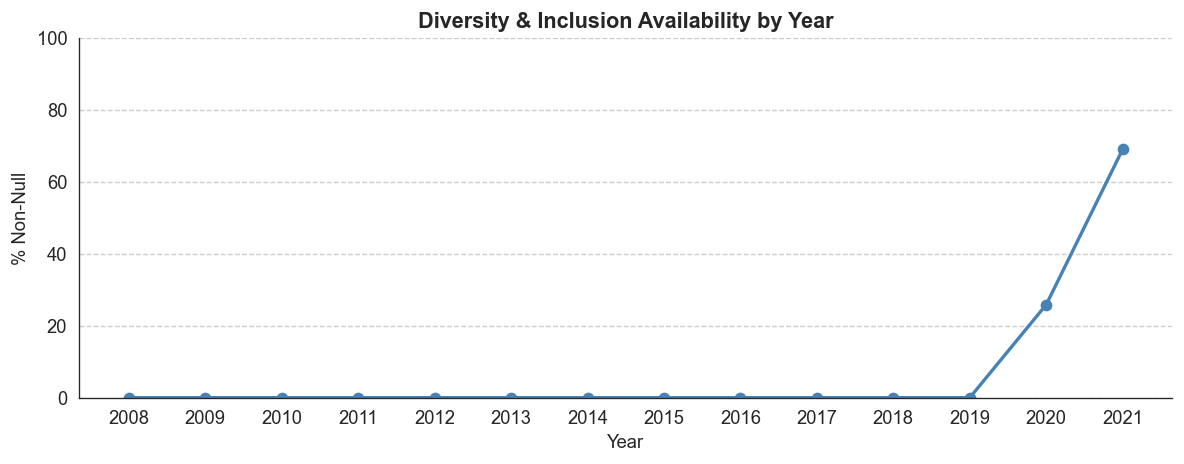

In [103]:
# --- VISUALISATION: diversity_inclusion availability by year ---
# Check whether the 83.8% missingness is temporal (field introduced later) or random
df["date_review"] = pd.to_datetime(df["date_review"])
di_by_year = df.groupby(df["date_review"].dt.year)["diversity_inclusion"].apply(
    lambda x: x.notna().mean() * 100
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(di_by_year.index, di_by_year.values, marker="o", color="steelblue", linewidth=2)
ax.set_title("Diversity & Inclusion Availability by Year")
ax.set_xlabel("Year")
ax.set_ylabel("% Non-Null")
ax.set_ylim(0, 100)
ax.set_xticks(di_by_year.index)
ax.yaxis.grid(True, linestyle='--', alpha=0.4, color='grey')  # Horizontal only
plt.tight_layout()
save_fig("eda_diversity_inclusion_by_year")
plt.show()
# Takeaway: diversity_inclusion was introduced mid-dataset — missingness is structural, not random.

In [104]:
# Non-null % per year for all columns with missing data
# Helps identify a cutoff year where most features are well-populated
missing_cols = ["work_life_balance", "culture_values", "diversity_inclusion",
                "career_opp", "comp_benefits", "senior_mgmt", "location"]

year = df["date_review"].dt.year
availability = year.groupby(year).apply(lambda _: pd.Series(dtype="float64"))  # placeholder

rows = []
for yr in sorted(year.unique()):
    mask = year == yr
    row = {"year": yr, "n_reviews": mask.sum()}
    for col in missing_cols:
        row[col] = df.loc[mask, col].notna().mean() * 100
    rows.append(row)

avail_df = pd.DataFrame(rows).set_index("year")
avail_df.columns = ["n_reviews"] + [c.replace("_", " ") for c in missing_cols]

print("Non-null % per year for columns with missing data:")
print(avail_df.to_string(float_format=lambda x: f"{x:.1f}" if isinstance(x, float) else f"{x:,.0f}"))

Non-null % per year for columns with missing data:
      n_reviews  work life balance  culture values  diversity inclusion  career opp  comp benefits  senior mgmt  location
year                                                                                                                     
2008       5693              100.0             0.0                  0.0       100.0          100.0        100.0      93.2
2009       5958              100.0             0.0                  0.0       100.0          100.0        100.0      71.9
2010      10110              100.0             0.0                  0.0       100.0          100.0        100.0      62.7
2011      10886              100.0             0.0                  0.0       100.0          100.0        100.0      60.6
2012      20587               93.4            65.7                  0.0        94.4           93.5         93.0      68.5
2013      24696               91.4            91.1                  0.0        91.3           9

In [105]:
# Checking the missingness pattern vs target
sub_rating_cols = ["work_life_balance", "culture_values", "diversity_inclusion",
                   "career_opp", "comp_benefits", "senior_mgmt"]

miss_by_target = df.groupby("recommend_label")[sub_rating_cols].apply(
    lambda x: x.isnull().mean() * 100
).round(1)
miss_by_target = miss_by_target.reindex(["Positive", "No Opinion", "Negative"])

print("% missing by recommend class:")
display(miss_by_target)
# Takeaway: Missingness is target-dependent — "No Opinion" reviews have ~55-61% missing
# sub-ratings vs ~3-9% for Positive/Negative. 

% missing by recommend class:


,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt
recommend_label,,,,,,
Positive,3.3,7.8,80.6,3.3,3.4,3.8
No Opinion,55.7,61.0,89.5,54.6,55.5,56.8
Negative,3.1,8.6,84.0,3.2,3.1,3.6


In [106]:
# Check correlation of missingness within subratings
# Confirm whether people skip ALL sub-ratings together (block missingness)
miss_indicators = df[sub_rating_cols].isnull().astype(int)
miss_corr = miss_indicators.corr().round(3)

print("Correlation matrix of missingness indicators (isnull):")
display(miss_corr)

# Show min/max off-diagonal correlations for quick summary
mask = np.triu(np.ones_like(miss_corr, dtype=bool), k=0)
off_diag = miss_corr.where(~mask)
print(f"\nOff-diagonal range: {off_diag.min().min():.3f} to {off_diag.max().max():.3f}")
# Takeaway: Excluding diversity_inclusion, sub-rating missingness is highly correlated (0.9+) —
# reviewers skip all optional sub-ratings together, not individual ones. This is block-MAR.

Correlation matrix of missingness indicators (isnull):


,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt
work_life_balance,1.000,0.841,0.199,0.956,0.975,0.965
culture_values,0.841,1.000,0.236,0.824,0.839,0.840
diversity_inclusion,0.199,0.236,1.000,0.198,0.201,0.202
career_opp,0.956,0.824,0.198,1.000,0.962,0.943
comp_benefits,0.975,0.839,0.201,0.962,1.000,0.960
senior_mgmt,0.965,0.840,0.202,0.943,0.960,1.000



Off-diagonal range: 0.198 to 0.975


In [107]:
# Check missingness pattern vs employee status ---
# Compute employee status inline (temporary — full version created in section 2.5)
status_temp = df["current"].apply(lambda x: "Current" if "Current" in str(x) else "Former")

miss_by_status = df.groupby(status_temp)[sub_rating_cols].apply(
    lambda x: x.isnull().mean() * 100
).round(1)

print("% missing by employee status:")
display(miss_by_status)
# Takeaway: Former employees have slightly higher missingness (~2-3pp) — minor difference,
# unlikely to bias imputation. Missingness is primarily temporal/block, not status-driven.

% missing by employee status:


,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt
current,,,,,,
Current,17.1,22.7,83.6,16.9,17.1,17.8
Former,19.0,23.1,84.1,18.6,19.0,19.8


Sub-rating completeness (5 core sub-ratings):
              Count  Percent
All present  637409     76.0
Partial       58941      7.0
All missing  142216     17.0
Saved: eda_recommend_by_completeness_v2.png


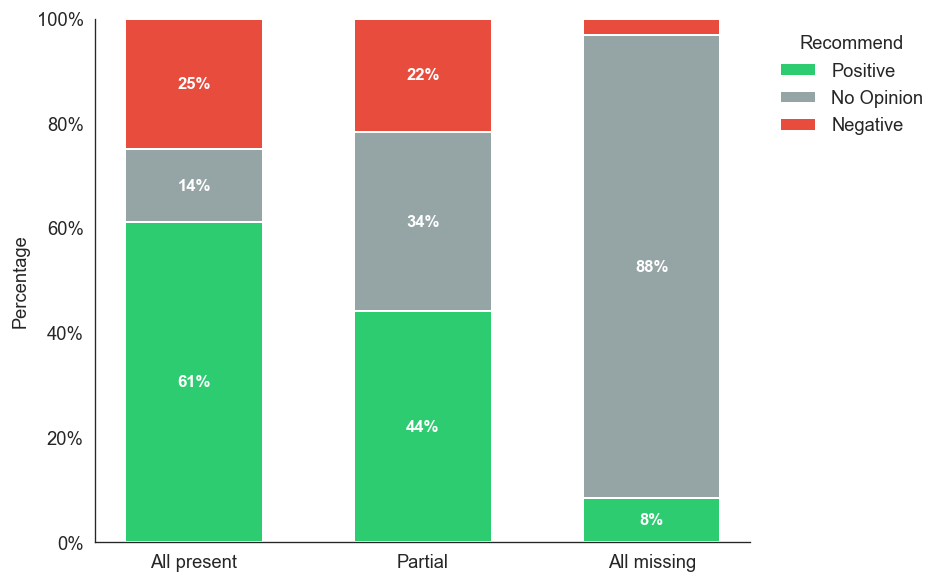

In [148]:
# --- Sub-rating completeness analysis ---
core_sub = ["work_life_balance", "culture_values", "career_opp", "comp_benefits", "senior_mgmt"]
n_present = df[core_sub].notna().sum(axis=1)
completeness_temp = pd.Series("Partial", index=df.index)
completeness_temp[n_present == 5] = "All present"
completeness_temp[n_present == 0] = "All missing"
comp_counts = completeness_temp.value_counts().reindex(["All present", "Partial", "All missing"])
comp_pct = (comp_counts / len(df) * 100).round(1)
print("Sub-rating completeness (5 core sub-ratings):")
print(pd.DataFrame({"Count": comp_counts, "Percent": comp_pct}))

# --- VISUALISATION: Recommend distribution by sub-rating completeness ---
fig, ax = plt.subplots(figsize=(8, 5))

# Data prep
n_missing = df[core_sub].isnull().sum(axis=1)
df["completeness_group"] = pd.cut(n_missing, bins=[-1, 0, 4, 5], 
                                   labels=["All present", "Partial", "All missing"])
ct_plot = pd.crosstab(df["completeness_group"], df["recommend_label"], normalize="index")
ct_plot = ct_plot.reindex(columns=TARGET_ORDER)
ct_plot = ct_plot.reindex(["All present", "Partial", "All missing"])

# Stacked bar
bottom = np.zeros(len(ct_plot))
x = np.arange(len(ct_plot))
for rec_class in TARGET_ORDER:
    values = ct_plot[rec_class].values
    bars = ax.bar(x, values, bottom=bottom, label=rec_class,
                  color=TARGET_COLORS[rec_class], edgecolor="white", linewidth=1.2,
                  width=0.6)
    
    # Label inside each segment
    for i, (bar, val) in enumerate(zip(bars, values)):
        if val > 0.06:
            ax.annotate(f"{val:.0%}",
                        xy=(bar.get_x() + bar.get_width() / 2, bottom[i] + val / 2),
                        ha="center", va="center", fontsize=10,
                        color="white", fontweight="bold")
    bottom += values

ax.set_xticks(x)
ax.set_xticklabels(["All present", "Partial", "All missing"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.set_ylabel("Percentage")
ax.set_xlabel("")
ax.legend(title="Recommend", frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_ylim(0, 1.0)

plt.tight_layout()
save_fig("eda_recommend_by_completeness")
plt.show()

In [ ]:
# --- Class balance impact: what happens if we drop all-missing rows? ---
# Exploratory only — not actually dropping rows

# Current distribution
current_3class = df["recommend_label"].value_counts().reindex(["Positive", "No Opinion", "Negative"])
current_pct = (current_3class / len(df) * 100).round(1)

# Identify all-missing rows
all_missing_mask = df[core_sub].isnull().all(axis=1)

# What gets dropped?
dropped_dist = df.loc[all_missing_mask, "recommend_label"].value_counts().reindex(
    ["Positive", "No Opinion", "Negative"]
)
dropped_pct_of_dropped = (dropped_dist / dropped_dist.sum() * 100).round(1)

# After-drop distribution
after_3class = current_3class - dropped_dist
n_after = len(df) - all_missing_mask.sum()
after_pct = (after_3class / n_after * 100).round(1)
shift = after_pct - current_pct

print("=== Impact of dropping all-missing rows (142K reviews) ===\n")
impact_df = pd.DataFrame({
    "Before": current_3class,
    "Before %": current_pct,
    "Dropped": dropped_dist,
    "% of dropped": dropped_pct_of_dropped,
    "After": after_3class,
    "After %": after_pct,
    "Shift (pp)": shift.round(1)
})
display(impact_df)

# Binary split comparison
pos_before = current_3class["Positive"]
not_pos_before = current_3class["No Opinion"] + current_3class["Negative"]
pos_after = after_3class["Positive"]
not_pos_after = after_3class["No Opinion"] + after_3class["Negative"]

print(f"\nBinary split (Positive vs Not Positive):")
print(f"  Before: {pos_before:,} ({pos_before/len(df)*100:.1f}%) vs "
      f"{not_pos_before:,} ({not_pos_before/len(df)*100:.1f}%)")
print(f"  After:  {pos_after:,} ({pos_after/n_after*100:.1f}%) vs "
      f"{not_pos_after:,} ({not_pos_after/n_after*100:.1f}%)")
print(f"  Shift:  Positive {pos_after/n_after*100 - pos_before/len(df)*100:+.1f}pp")

# Note: dropped rows are disproportionately "No Opinion" — check
print(f"\nDropped rows composition: {dropped_pct_of_dropped['No Opinion']:.0f}% No Opinion, "
      f"{dropped_pct_of_dropped['Positive']:.0f}% Positive, "
      f"{dropped_pct_of_dropped['Negative']:.0f}% Negative")

=== Impact of dropping all-missing rows (142K reviews) ===



,Before,Before %,Dropped,% of dropped,After,After %,Shift (pp)
recommend_label,,,,,,,
Positive,427865,51.0,11960,8.4,415905,59.7,8.7
No Opinion,234248,27.9,125823,88.5,108425,15.6,-12.3
Negative,176453,21.0,4433,3.1,172020,24.7,3.7



Binary split (Positive vs Not Positive):
  Before: 427,865 (51.0%) vs 410,701 (49.0%)
  After:  415,905 (59.7%) vs 280,445 (40.3%)
  Shift:  Positive +8.7pp

Dropped rows composition: 88% No Opinion, 8% Positive, 3% Negative


**Takeaway — Missing Values & Data Quality:**
- **Structural missingness:** `diversity_inclusion` only exists from 2020 (83.8% missing overall); `culture_values` missing before 2012.
- **Target-dependent:** “No Opinion” reviews have 55–61% missing sub-ratings vs 3–9% for Positive/Negative — missingness is not random.
- **Block pattern:** Sub-rating nulls are correlated 0.9+ — reviewers skip ALL optional fields together.
- **142K rows (17%) have all 5 core sub-ratings missing** — 88% of these are “No Opinion” (disengaged reviewers).
- **Class balance impact:** Dropping all-missing shifts binary split from 51/49 to 60/40. Acceptable but noted; stratified sampling will preserve post-filtering balance.

---
## 2.4 Numeric Features (Sub-Ratings)

Distributions and correlations for the 6 sub-rating columns.

In [110]:
# Descriptive statistics
rating_cols = ["overall_rating", "work_life_balance", "culture_values",
               "diversity_inclusion", "career_opp", "comp_benefits", "senior_mgmt"]

desc = df[rating_cols].describe().round(2)
print("Descriptive statistics for numeric ratings:")
display(desc)

# Skewness
skew = df[rating_cols].skew().round(3)
print("\nSkewness (negative = left-skewed, positive = right-skewed):")
print(skew)

Descriptive statistics for numeric ratings:


,overall_rating,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt
count,838566.00,688672.00,647193.00,136066.00,691065.00,688484.00,682690.00
mean,3.66,3.38,3.59,3.97,3.46,3.40,3.18
std,1.17,1.31,1.32,1.19,1.27,1.22,1.33
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,3.00,2.00,3.00,3.00,3.00,3.00,2.00
50%,4.00,4.00,4.00,4.00,4.00,3.00,3.00
75%,5.00,4.00,5.00,5.00,5.00,4.00,4.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00



Skewness (negative = left-skewed, positive = right-skewed):
overall_rating        -0.680
work_life_balance     -0.375
culture_values        -0.615
diversity_inclusion   -1.041
career_opp            -0.460
comp_benefits         -0.379
senior_mgmt           -0.239
dtype: float64


Saved: eda_rating_distributions_v1.png


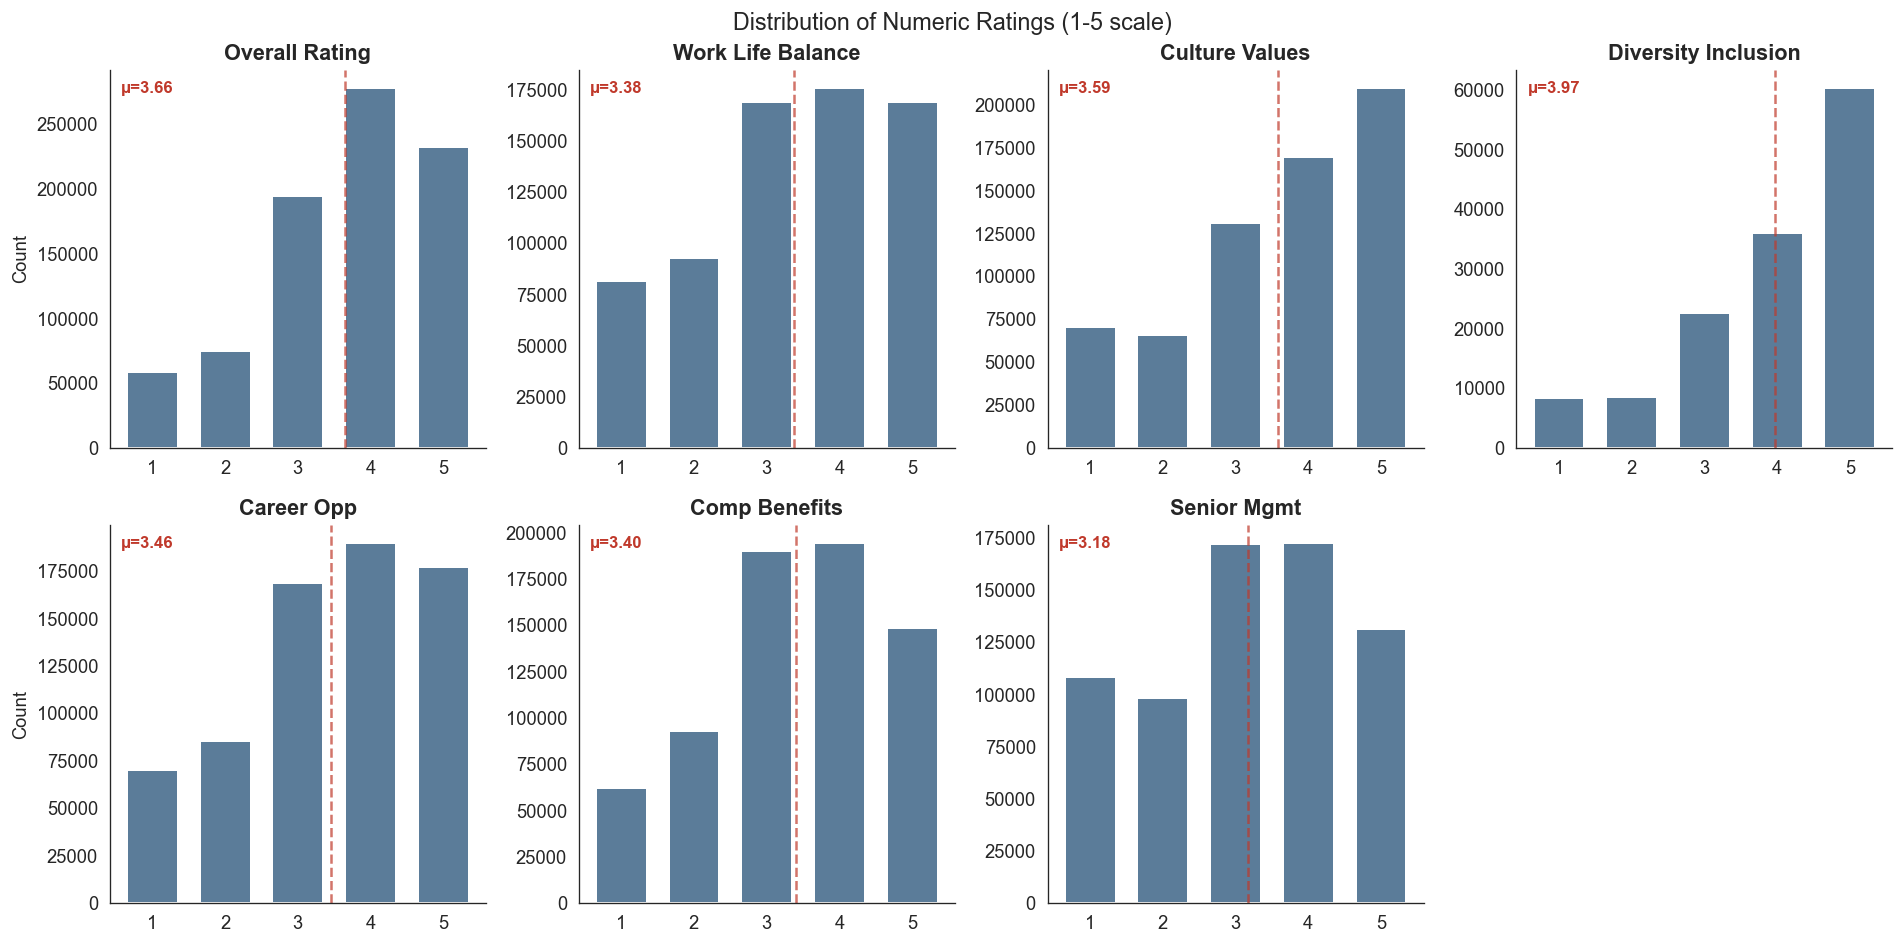

In [ ]:
# --- VISUALISATION: Sub-rating distributions ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
BAR_COLOR = "#5b7c99"

for i, col in enumerate(rating_cols):
    ax = axes[i]
    data = df[col].dropna()
    val_counts = data.value_counts().sort_index()
    
    ax.bar(val_counts.index, val_counts.values,
           color=BAR_COLOR, edgecolor='white', linewidth=1.2, width=0.7)
    
    # Mean line
    mean_val = data.mean()
    ax.axvline(mean_val, color="#c0392b", linestyle='--', linewidth=1.5, alpha=0.7)
    
    # μ annotation
    ax.text(0.03, 0.97, f'μ={mean_val:.2f}', transform=ax.transAxes,
            ha='left', va='top', fontsize=10, color="#c0392b", fontweight='bold')
    
    ax.set_title(col.replace('_', ' ').title())
    ax.set_xlabel('')
    ax.set_ylabel('Count' if i % 4 == 0 else '')
    ax.set_xticks([1, 2, 3, 4, 5])
    # REMOVED: ax.grid(False) — now default

axes[-1].set_visible(False)
fig.suptitle('Distribution of Numeric Ratings (1-5 scale)', fontsize=14)
plt.tight_layout()
plt.subplots_adjust(top=0.92)
save_fig('eda_rating_distributions')  
plt.show()

Saved: eda_correlations_combined_v1.png


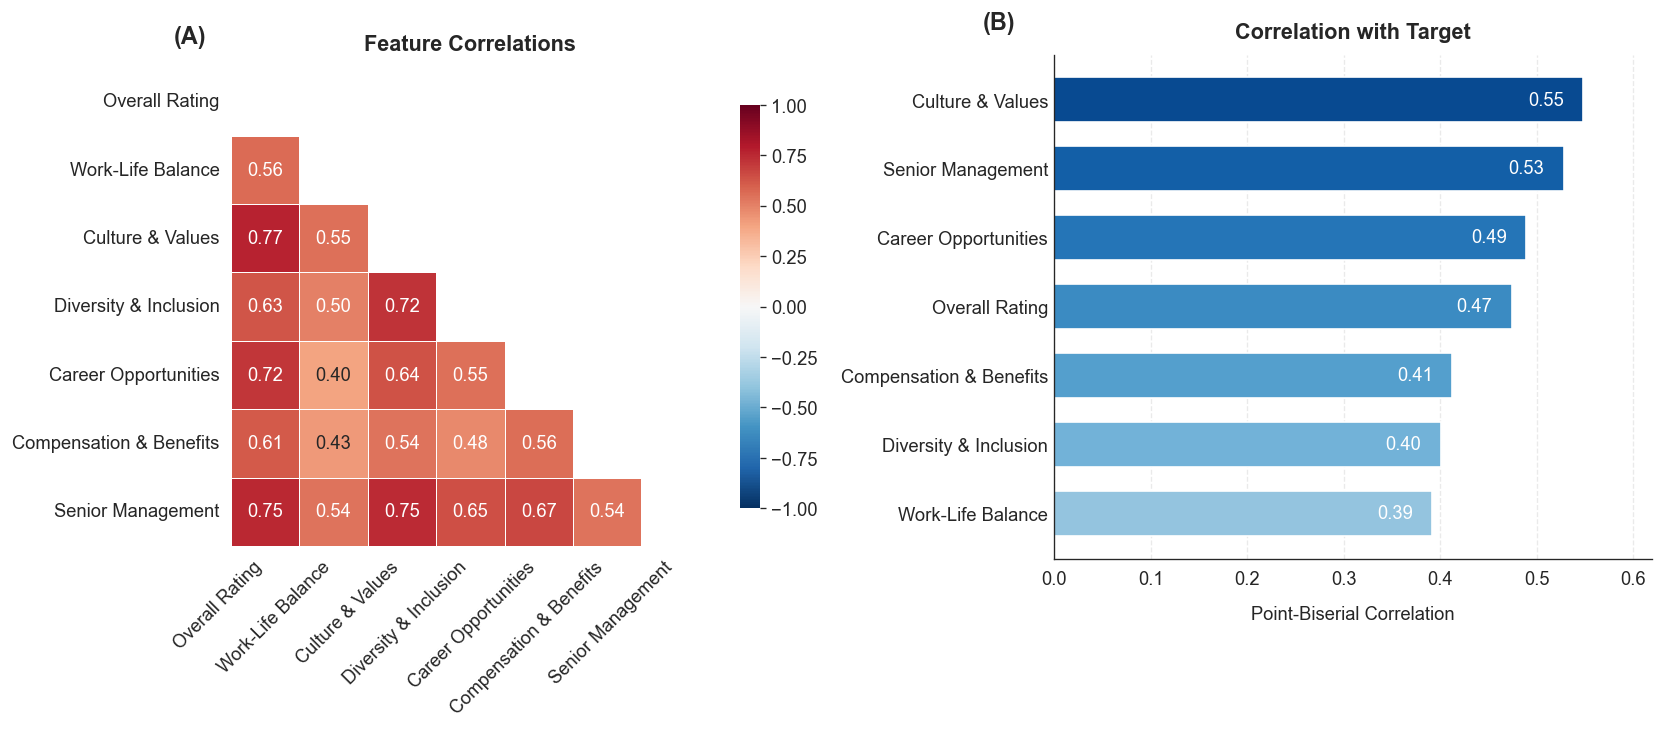

In [141]:
# --- VISUALISATION: Combined EDA Figure (Correlation Heatmap + Target Correlations) ---

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ============ PANEL A: Correlation Heatmap ============
ax_a = axes[0]

corr_matrix = df[rating_cols].corr()
corr_matrix.index = corr_matrix.index.map(RATING_LABELS)
corr_matrix.columns = corr_matrix.columns.map(RATING_LABELS)

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            ax=ax_a, cbar_kws={"shrink": 0.8})

ax_a.set_title("Feature Correlations", pad=10)
ax_a.set_xticklabels(ax_a.get_xticklabels(), rotation=45, ha='right')
ax_a.set_yticklabels(ax_a.get_yticklabels(), rotation=0)

# Panel label
ax_a.text(-0.12, 1.05, '(A)', transform=ax_a.transAxes,
          fontsize=14, fontweight='bold')

# ============ PANEL B: Point-Biserial Correlations ============
ax_b = axes[1]

binary_target_temp = (df["recommend"] == "v").astype(int)

correlations = {}
for col in rating_cols:
    valid_mask = df[col].notna()
    r, _ = pointbiserialr(binary_target_temp[valid_mask], df[col][valid_mask])
    correlations[col] = r

corr_series = pd.Series(correlations).sort_values()
display_names = [RATING_LABELS[name] for name in corr_series.index]

colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(corr_series)))
bars_b = ax_b.barh(display_names, corr_series.values, color=colors, height=0.65)

# Value labels inside bars
for bar, val in zip(bars_b, corr_series.values):
    ax_b.text(val - 0.02, bar.get_y() + bar.get_height()/2,
              f'{val:.2f}', va='center', ha='right',
              fontsize=11, fontweight='medium', color='white')

ax_b.set_xlim(0, 0.62)
ax_b.set_xlabel('Point-Biserial Correlation', labelpad=10)
ax_b.xaxis.set_major_locator(plt.MultipleLocator(0.1))
ax_b.set_title("Correlation with Target", pad=10)
ax_b.tick_params(axis='y', length=0)
ax_b.xaxis.grid(True, linestyle='--', alpha=0.4)
ax_b.set_axisbelow(True)
sns.despine(ax=ax_b)

# Panel label
ax_b.text(-0.12, 1.05, '(B)', transform=ax_b.transAxes,
          fontsize=14, fontweight='bold')

plt.tight_layout()
save_fig("eda_correlations_combined")
plt.show()

**Takeaway**
**Multicollinearity:**
- Several sub-rating pairs show **correlations above 0.7**, notably `culture_values` ↔ `senior_mgmt` (r=0.75) and `culture_values` ↔ `diversity_inclusion` (r=0.72).
- This is not surprising as perceptions of company culture, leadership quality, and inclusiveness are conceptually overlapping aspects of workplace environment.
- **Implication for next stages:** High multicollinearity won't harm tree-based models (XGBoost, Random Forest) but could inflate coefficients in logistic regression. Regularisation can help mitigate this.

**Target correlation:** 
- `culture_values` (r = 0.55) and `senior_mgmt` (r = 0.53) show the strongest association with recommending the employer; all other sub-ratings show moderate positive correlation (r = 0.39–0.49).

In [114]:
# Mean sub-ratings by recommend class — how do ratings differ?
print("Mean ratings by recommend class:")
means_by_rec = df.groupby("recommend_label")[rating_cols].mean().round(2)
display(means_by_rec.reindex(["Positive", "No Opinion", "Negative"]))

Mean ratings by recommend class:


,overall_rating,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt
recommend_label,,,,,,,
Positive,4.20,3.79,4.17,4.35,3.97,3.81,3.75
No Opinion,3.73,3.31,3.57,3.93,3.43,3.28,3.14
Negative,2.23,2.41,2.18,2.88,2.25,2.48,1.82


**Takeaway — Numeric Features:**
- **Response patterns:** All sub-ratings concentrate at the upper end of the 1–5 scale (most ratings fall between 3 and 5). `diversity_inclusion` shows the strongest ceiling effect (skewness −1.04).
- `overall_rating` **leakage risk**: r = 0.47 with target — moderately correlated but captures a distinct concept (holistic satisfaction score, independently marked). **Keep with ablation test.**

---
## 2.5 Leakage Risk Analysis

Checking whether opinion variables collected as part of the review show construct overlap with the target, risking leakage.

In [115]:
# Quick CEO approval distribution check
print("CEO approval distribution:")
ceo_counts = df["ceo_approv"].value_counts()
ceo_pct = (ceo_counts / len(df) * 100).round(1)
print(pd.DataFrame({"Count": ceo_counts, "Percent": ceo_pct}))
print("\nCodes: v=Approve, r=Mild, o=No Opinion, x=Disapprove")

CEO approval distribution:
             Count  Percent
ceo_approv                 
o           311433     37.1
v           286695     34.2
r           176930     21.1
x            63508      7.6

Codes: v=Approve, r=Mild, o=No Opinion, x=Disapprove


In [116]:
# Contruct overlap check
print("\n=== Construct Overlap Check: ceo_approv and outlook ===")
# Map these too for readability
label_map_4 = {"v": "Positive", "r": "Mild", "o": "No Opinion", "x": "Negative"}
for col in ["ceo_approv", "outlook"]:
    df[f"{col}_label"] = df[col].map(label_map_4)
    ct = pd.crosstab(df[f"{col}_label"], df["recommend_label"], normalize="index").round(3)
    ct = ct.reindex(columns=["Positive", "No Opinion", "Negative"])
    print(f"\nP(recommend | {col}):")
    display(ct)



=== Construct Overlap Check: ceo_approv and outlook ===

P(recommend | ceo_approv):


recommend_label,Positive,No Opinion,Negative
ceo_approv_label,,,
Mild,0.538,0.066,0.396
Negative,0.169,0.046,0.786
No Opinion,0.232,0.672,0.096
Positive,0.871,0.036,0.093



P(recommend | outlook):


recommend_label,Positive,No Opinion,Negative
outlook_label,,,
Mild,0.574,0.030,0.396
Negative,0.161,0.020,0.819
No Opinion,0.164,0.761,0.075
Positive,0.917,0.012,0.070


**Takeaway — Leakage Risk:**
- `ceo_approv`: 87% of “Positive” CEO approval also recommend. High construct overlap, but CEO approval is conceptually distinct from recommending the company. **Keep with ablation test.**
- `outlook`: 92% of “Positive” outlook also recommend. This is the strongest construct overlap — “positive outlook on the business” and “would recommend” are near-synonymous. **Drop** due to leakage risk.

---
## 2.6 Text Features

Three text columns are available: `headline`, `pros`, and `cons`. This section examines their completeness, length distributions, and potential data quality issues.

In [117]:
# Missing / empty text values
text_cols = ["headline", "pros", "cons"]

print("Text column completeness:")
for col in text_cols:
    n_null = df[col].isnull().sum()
    n_empty = (df[col].fillna("").str.strip() == "").sum()
    print(f"  {col}: {n_null:,} null, {n_empty:,} empty/whitespace-only ({n_empty / len(df) * 100:.2f}%)")

Text column completeness:
  headline: 2,590 null, 2,590 empty/whitespace-only (0.31%)
  pros: 2 null, 2 empty/whitespace-only (0.00%)
  cons: 13 null, 13 empty/whitespace-only (0.00%)


In [118]:
# Text length distributions
for col in text_cols:
    df[f"{col}_len"] = df[col].fillna("").str.len()

# Word counts too
for col in text_cols:
    df[f"{col}_words"] = df[col].fillna("").str.split().str.len()

print("Character length summary:")
display(df[[f"{c}_len" for c in text_cols]].describe().round(0))

print("\nWord count summary:")
display(df[[f"{c}_words" for c in text_cols]].describe().round(0))

Character length summary:


,headline_len,pros_len,cons_len
count,838566.0,838566.0,838566.0
mean,23.0,92.0,123.0
std,18.0,114.0,227.0
min,0.0,0.0,0.0
25%,12.0,39.0,37.0
50%,19.0,56.0,57.0
75%,29.0,105.0,123.0
max,519.0,18193.0,10777.0



Word count summary:


,headline_words,pros_words,cons_words
count,838566.0,838566.0,838566.0
mean,4.0,15.0,21.0
std,3.0,20.0,40.0
min,0.0,0.0,0.0
25%,2.0,6.0,6.0
50%,3.0,9.0,9.0
75%,5.0,17.0,21.0
max,93.0,3153.0,1917.0


In [119]:
# Short review analysis — informs minimum word count for BERTopic
# Very short reviews won't produce meaningful topics
thresholds = [1, 3, 5, 10]

pros_words = df["pros"].fillna("").str.split().str.len()
cons_words = df["cons"].fillna("").str.split().str.len()

print("Short review counts by word count threshold:")
print(f"{'Threshold':<12} {'Pros Count':>12} {'Pros %':>8} {'Cons Count':>12} {'Cons %':>8}")
print("-" * 56)
for t in thresholds:
    pros_below = (pros_words < t).sum()
    cons_below = (cons_words < t).sum()
    print(f"< {t:<3} words  {pros_below:>12,} {pros_below / len(df) * 100:>7.2f}% "
          f"{cons_below:>12,} {cons_below / len(df) * 100:>7.2f}%")
# Takeaway: reviews below ~5 words are unlikely to produce meaningful BERTopic clusters.

Short review counts by word count threshold:
Threshold      Pros Count   Pros %   Cons Count   Cons %
--------------------------------------------------------
< 1   words             2    0.00%           13    0.00%
< 3   words            35    0.00%           94    0.01%
< 5   words         5,813    0.69%        5,583    0.67%
< 10  words       464,040   55.34%      420,741   50.17%


Saved: eda_text_lengths_v1.png


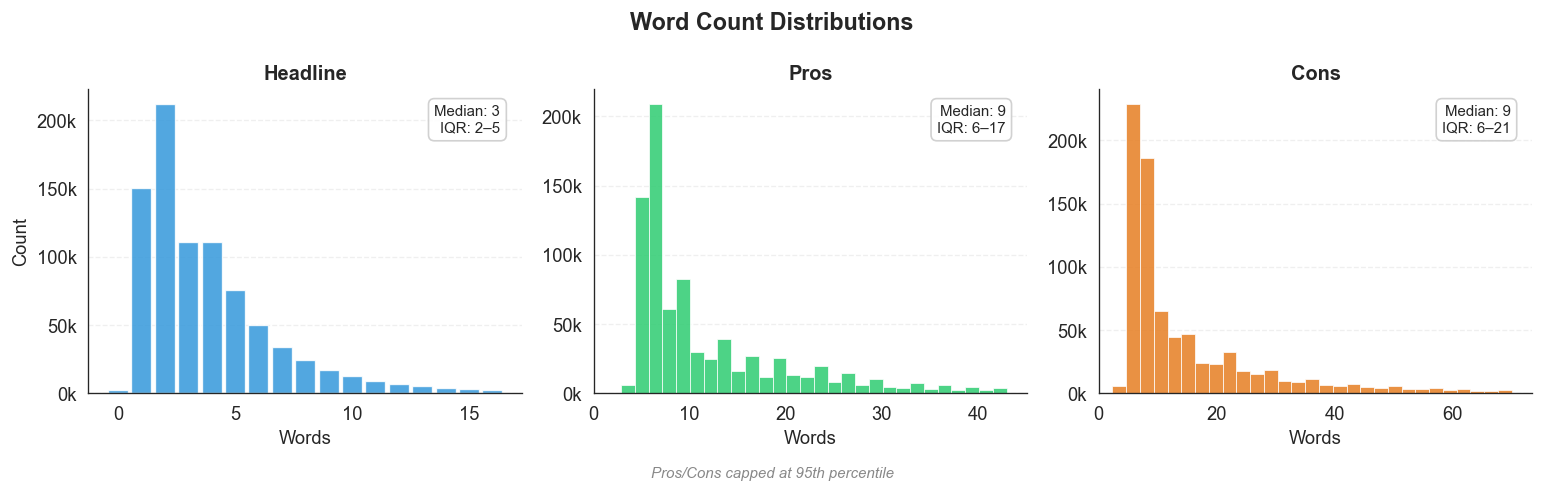

In [120]:
# --- VISUALISATION: Text length distributions ---
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

text_cols = ['headline', 'pros', 'cons']
colors = ['#3498db', '#2ecc71', '#e67e22']

for i, col in enumerate(text_cols):
    word_col = f"{col}_words"
    
    # Tighter cap for pros/cons
    if col == 'headline':
        cap = df[word_col].quantile(0.99)
    else:
        cap = df[word_col].quantile(0.95)
    
    data = df[word_col][df[word_col] <= cap].dropna()
    
    if col == 'headline':
        bins = np.arange(0, data.max() + 2) - 0.5
        axes[i].hist(data, bins=bins, color=colors[i], alpha=0.85, edgecolor='white', linewidth=0.8, rwidth=0.85)
    else:
        axes[i].hist(data, bins=30, color=colors[i], alpha=0.85, edgecolor='white', linewidth=0.5)
        axes[i].set_xlim(0, cap * 1.05)
    
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=12)  # Intentionally smaller; fontweight from rcParams
    axes[i].set_xlabel("Words")
    axes[i].set_ylabel("Count" if i == 0 else "")
    axes[i].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000:.0f}k'))
    
    # Stats box (use full data for accurate stats)
    full_data = df[word_col].dropna()
    median = full_data.median()
    q25, q75 = full_data.quantile(0.25), full_data.quantile(0.75)
    stats_text = f"Median: {median:.0f}\nIQR: {q25:.0f}–{q75:.0f}"
    axes[i].text(0.95, 0.95, stats_text, transform=axes[i].transAxes, 
                 fontsize=9, va='top', ha='right', 
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.9, edgecolor='#cccccc'))
    
    axes[i].yaxis.grid(True, linestyle='--', alpha=0.3)  # Opt-in y-grid for histograms
    axes[i].set_axisbelow(True)

plt.suptitle("Word Count Distributions", fontsize=14, fontweight='bold')  # suptitle needs explicit fontweight
fig.text(0.5, 0.01, "Pros/Cons capped at 95th percentile", 
         ha='center', fontsize=9, color='#888888', style='italic')
plt.tight_layout(rect=[0, 0.03, 1, 1])
save_fig("eda_text_lengths")
plt.show()

Saved: eda_text_length_by_target_v1.png


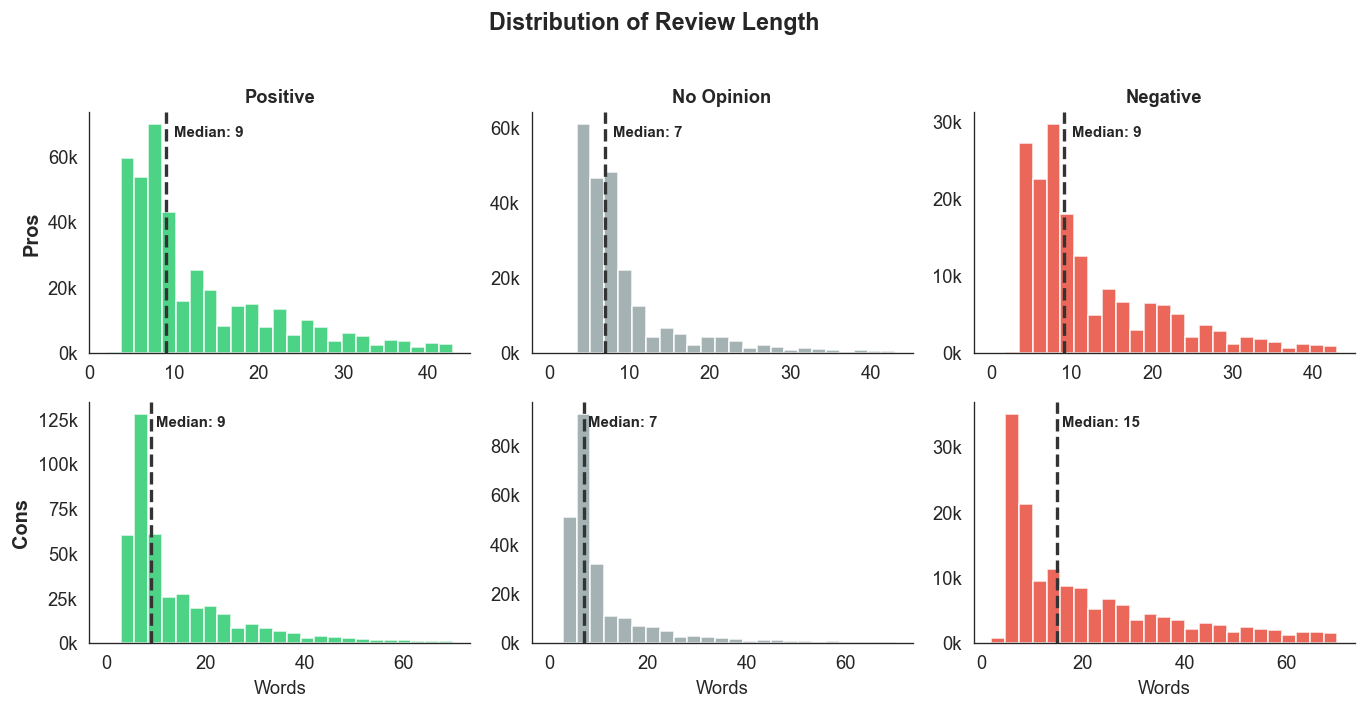

In [121]:
# --- VISUALISATION: Pros & cons word count by recommend class ---
fig, axes = plt.subplots(2, 3, figsize=(12, 6))

for row, (col, label) in enumerate([("pros_words", "Pros"), ("cons_words", "Cons")]):
    cap = df[col].quantile(0.95)
    
    for i, cls in enumerate(TARGET_ORDER):  # Use constant
        subset = df.loc[(df["recommend_label"] == cls) & (df[col] <= cap), col]
        
        axes[row, i].hist(subset, bins=25, color=TARGET_COLORS[cls], alpha=0.85, edgecolor='white')
        
        # Median line
        med = subset.median()
        axes[row, i].axvline(med, color='#333333', linestyle='--', linewidth=2)
        axes[row, i].text(med + 1, axes[row, i].get_ylim()[1] * 0.9, f'Median: {med:.0f}',
                          fontsize=9, fontweight='bold')
        
        axes[row, i].set_title(cls if row == 0 else "", fontsize=11)  
        axes[row, i].set_xlabel("Words" if row == 1 else "")
        axes[row, i].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000:.0f}k'))
    
    axes[row, 0].set_ylabel(label, fontsize=12, fontweight='bold')

fig.suptitle("Distribution of Review Length", fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0.04, 0, 1, 0.96])
save_fig("eda_text_length_by_target")
plt.show()

In [122]:
# --- TEXT LEAKAGE CHECK ---
# Do people write "recommend" or "would not recommend" in their reviews?
# This could leak the target if we use text as features.

# Combine pros and cons for searching
pros_text = df["pros"].fillna("").str.lower()
cons_text = df["cons"].fillna("").str.lower()
headline_text = df["headline"].fillna("").str.lower()

# Search patterns
patterns = {
    "would recommend": r"would recommend",
    "would not recommend": r"would not recommend",
    "wouldn't recommend": r"wouldn'?t recommend",
    "highly recommend": r"highly recommend",
    "do not recommend": r"do not recommend",
    "don't recommend": r"don'?t recommend",
    "i recommend": r"i recommend",
    "not recommend": r"not recommend",
    "recommend": r"\brecommend\b",
}

print("=== Text Leakage Check: 'recommend' phrases in review text ===")
print(f"{'Pattern':<25} {'Pros':>10} {'Cons':>10} {'Headline':>10} {'Total':>10}")
print("-" * 70)

for label, pattern in patterns.items():
    n_pros = pros_text.str.contains(pattern, regex=True, na=False).sum()
    n_cons = cons_text.str.contains(pattern, regex=True, na=False).sum()
    n_head = headline_text.str.contains(pattern, regex=True, na=False).sum()
    total = n_pros + n_cons + n_head
    print(f"{label:<25} {n_pros:>10,} {n_cons:>10,} {n_head:>10,} {total:>10,}")

# Overall: any mention of "recommend" in any text field
any_recommend = (
    pros_text.str.contains(r"\brecommend\b", regex=True, na=False) |
    cons_text.str.contains(r"\brecommend\b", regex=True, na=False) |
    headline_text.str.contains(r"\brecommend\b", regex=True, na=False)
)
print(f"\nRows with any 'recommend' mention: {any_recommend.sum():,} ({any_recommend.sum() / len(df) * 100:.1f}%)")

=== Text Leakage Check: 'recommend' phrases in review text ===
Pattern                         Pros       Cons   Headline      Total
----------------------------------------------------------------------
would recommend                  760        274        312      1,346
would not recommend               52        404        316        772
wouldn't recommend                37        185        198        420
highly recommend                 550        115        284        949
do not recommend                  12         87        121        220
don't recommend                   19         61         75        155
i recommend                      117        104         50        271
not recommend                     99        740        895      1,734
recommend                      2,135      1,783      1,880      5,798

Rows with any 'recommend' mention: 5,678 (0.7%)


In [123]:
# Cross-check: do text leakage mentions align with actual recommend class?
df["has_recommend_text"] = any_recommend
print("Recommend class distribution for reviews mentioning 'recommend':")
ct = pd.crosstab(df["has_recommend_text"], df["recommend_label"], normalize="index").round(3)
ct = ct.reindex(columns=["Positive", "No Opinion", "Negative"])
display(ct)

Recommend class distribution for reviews mentioning 'recommend':


recommend_label,Positive,No Opinion,Negative
has_recommend_text,,,
False,0.511,0.280,0.209
True,0.444,0.162,0.394


In [124]:
# --- Sample Reviews ---
# Print 10 reviews across different recommend classes to understand content
print("=" * 80)
print("SAMPLE REVIEWS (stratified by recommend class)")
print("=" * 80)

for rec_class in ["Positive", "No Opinion", "Negative"]:
    subset = df[df["recommend_label"] == rec_class]
    # Sample 3 from Positive, 3 from No Opinion, 4 from Negative
    n_sample = 4 if rec_class == "Negative" else 3
    samples = subset.sample(n_sample, random_state=42)

    for _, row in samples.iterrows():
        print(f"\n--- [{rec_class}] | Overall: {row['overall_rating']} | Firm: {row['firm']} ---")
        print(f"Headline: {row['headline']}")
        print(f"Pros: {str(row['pros'])[:300]}")
        print(f"Cons: {str(row['cons'])[:300]}")
    print()

SAMPLE REVIEWS (stratified by recommend class)

--- [Positive] | Overall: 5 | Firm: Thomas-Cook ---
Headline: Amazing
Pros: Easy and relaxed day. Good to meet the other interviewees and gain advice. Lovely and friendly crew made you feel comfortable. The venue was amazing and easy to find literally just out side Gatwick north terminal although other assessment days may be else where
Cons: Waiting for decision after assessment day, the anxiety was crazy checking your emails every 5.3 seconds to see if they thought you did as good as you thought you did, then having to wait to get your training date

--- [Positive] | Overall: 3 | Firm: Thomson-Reuters ---
Headline: Work experience in Pangea3, Thomson Reuters, LMS
Pros: Initial learning is very good. Very detailed training program is followed for preparing contract drafting work
Cons: Stagnation after a few year.  Not many experienced people on the floor, at least in Noida. Pay package is not the best in the industry but average.

--- [Po

**Takeaway — Text Features:**
- **Completeness:** Minimal missing (<0.3% for all three text columns).
- **Length:** `headline` averages 4 words (too short for BERTopic); `pros` averages 15 words; `cons` averages 21 words.
- **Short reviews:** Consider minimum 5-word threshold for `pros`/`cons` — reviews below this unlikely to produce meaningful topics.
- **Text leakage:** Only 0.7% of reviews mention "recommend" — minimal risk.
- **Decision for Stage 3:** Drop `headline` (too short); filter `pros`/`cons` with <5 words.

---
## 2.7 Metadata Features

Exploring firm, job title, employee status, location, and temporal coverage.

In [125]:
# Current vs Former employee
df["employee_status"] = df["current"].apply(
    lambda x: "Current" if "Current" in str(x) else "Former"
)

print("Employee status (simplified):")
status_counts = df["employee_status"].value_counts()
status_pct = (status_counts / len(df) * 100).round(1)
print(pd.DataFrame({"Count": status_counts, "Percent": status_pct}))

# Recommend distribution by status
print("\nRecommend distribution by employee status:")
ct = pd.crosstab(df["employee_status"], df["recommend_label"], normalize="index").round(3)
ct = ct.reindex(columns=["Positive", "No Opinion", "Negative"])
display(ct)

Employee status (simplified):
                  Count  Percent
employee_status                 
Current          492122     58.7
Former           346444     41.3

Recommend distribution by employee status:


recommend_label,Positive,No Opinion,Negative
employee_status,,,
Current,0.560,0.267,0.173
Former,0.439,0.297,0.264


Saved: eda_recommend_by_status_v1.png


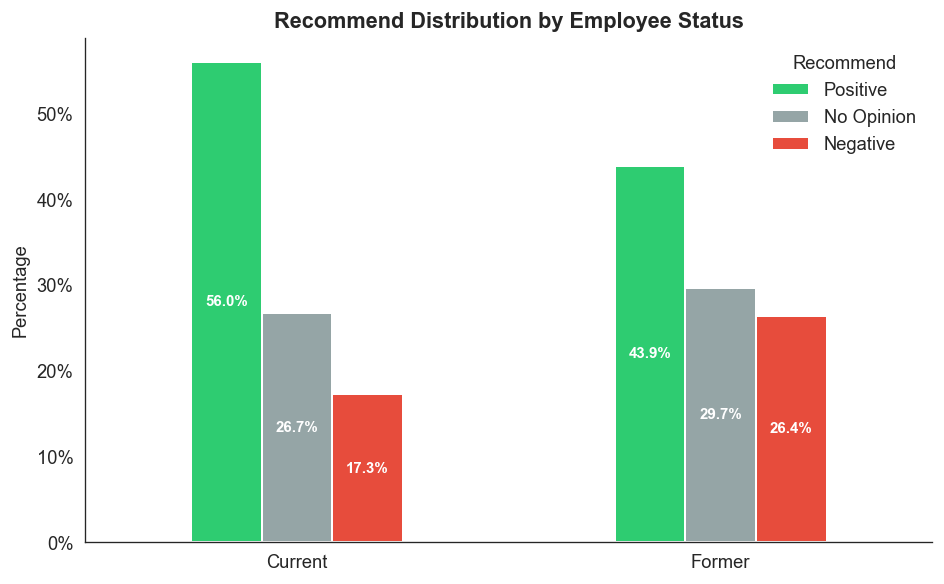

In [126]:
# --- VISUALISATION: Recommend distribution by employee status ---
ct_plot = pd.crosstab(df["employee_status"], df["recommend_label"], normalize="index")
ct_plot = ct_plot.reindex(columns=TARGET_ORDER)

fig, ax = plt.subplots(figsize=(8, 5))
ct_plot.plot.bar(ax=ax, color=[TARGET_COLORS[x] for x in TARGET_ORDER], 
                 edgecolor="white", linewidth=1.2)

ax.set_title("Recommend Distribution by Employee Status")
ax.set_xlabel("")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
ax.set_ylabel("Percentage")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Recommend", frameon=False)

# Percentage inside bars
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        if height > 0.08:
            ax.annotate(f"{height:.1%}",
                        xy=(bar.get_x() + bar.get_width() / 2, height / 2),
                        ha="center", va="center", fontsize=9, 
                        color="white", fontweight="bold")

plt.tight_layout()
save_fig("eda_recommend_by_status")
plt.show()


In [127]:
# Detailed current/former breakdown
print("Detailed employee status:")
print(df["current"].value_counts())

Detailed employee status:
current
Current Employee                           209599
Former Employee                            146133
Current Employee, more than 1 year          82749
Current Employee, more than 3 years         66471
Former Employee, more than 1 year           65687
Current Employee, less than 1 year          49603
Former Employee, more than 3 years          43614
Former Employee, less than 1 year           41874
Current Employee, more than 5 years         40155
Current Employee, more than 10 years        25029
Former Employee, more than 5 years          23017
Current Employee, more than 8 years         18506
Former Employee, more than 10 years         15411
Former Employee, more than 8 years          10686
Former Contractor, less than 1 year             6
Former Intern, less than 1 year                 5
Current Contractor, less than 1 year            3
Current Contractor, more than 1 year            3
Former Contractor                               2
Current Contract

In [128]:
# Quick check for potential firm name duplicates
firms = df["firm"].unique()
print(f"Unique firms: {len(firms)}")

# Sort alphabetically to spot near-duplicates visually
print("\nFirms sorted (scan for variants):")
for f in sorted(firms)[:50]:  # First 50
    print(f"  {f}")

Unique firms: 428

Firms sorted (scan for variants):
  AFH-Wealth-Management
  AJ-Bell
  ALDI
  AQA
  ASDA
  ASOS
  AXA-UK
  Abcam
  Abertawe-Bro-Morgannwg-University-Health-Board
  Accenture
  Accor
  Achieving-for-Children
  ActionCOACH
  Active-Care-Group
  Adecco
  Age-UK-The-National-Charity
  AlixPartners
  American-Express
  Amey
  Angard-Staffing
  Anglian-Water
  Anglo-American
  Animal-and-Plant-Health-Agency
  Aon
  Apple
  Arcadia
  Arnold-Clark
  AstraZeneca
  Aviva
  B-and-M-Retail
  B-and-Q
  BAT
  BBC
  BDO
  BHS
  BIS
  BNP-Paribas
  BNY-Mellon
  BP
  BPP-Holdings
  BT
  Babcock-International-Group
  Babylon-Health
  Bain-and-Company
  Balfour-Beatty
  Bannatyne-Group
  Barchester-Healthcare
  Barclays
  Barnardo-s
  Barnet-and-Chase-Farm-Hospitals-NHS-Trust


Unique firms: 428
Saved: eda_top_firms_v1.png


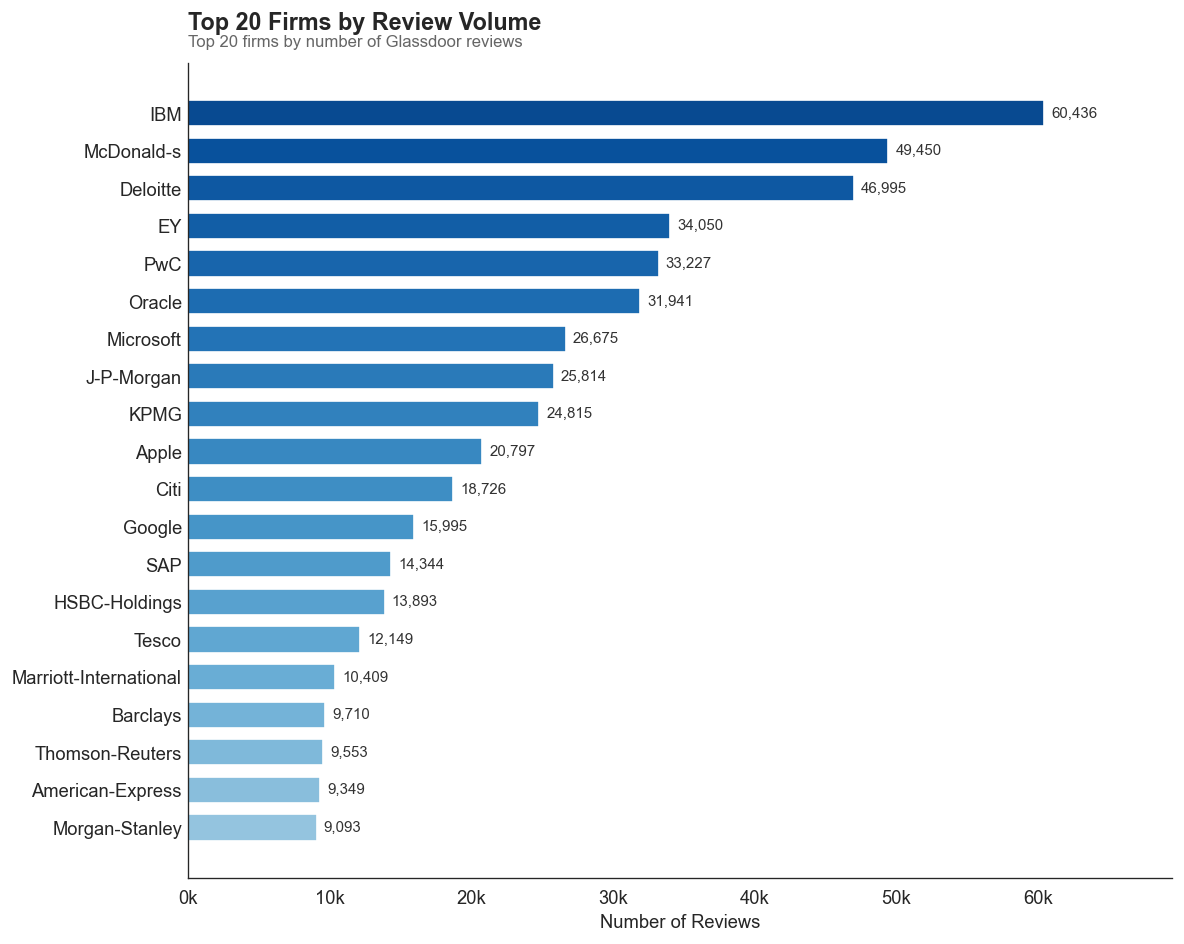

In [129]:
# Top 20 firms by review count
top_firms = df["firm"].value_counts().head(20)
print(f"Unique firms: {df['firm'].nunique():,}")

fig, ax = plt.subplots(figsize=(10, 8))

# Color gradient based on rank
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_firms)))[::-1]

bars = ax.barh(range(len(top_firms)), top_firms.values, color=colors, height=0.7)

# Value labels outside bars
for i, val in enumerate(top_firms.values):
    ax.text(val + 500, i, f'{val:,}', va='center', ha='left', 
            fontsize=9, fontweight='medium', color='#333333')

ax.set_yticks(range(len(top_firms)))
ax.set_yticklabels(top_firms.index)  # fontsize from rcParams
ax.set_xlabel("Number of Reviews")  # fontsize from rcParams
ax.invert_yaxis()
ax.set_xlim(0, top_firms.max() * 1.15)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000:.0f}k'))
ax.tick_params(axis='y', length=0)

ax.set_title("Top 20 Firms by Review Volume", fontsize=14, loc='left', pad=20)  # fontweight from rcParams
ax.text(0, 1.02, "Top 20 firms by number of Glassdoor reviews", transform=ax.transAxes,
        fontsize=10, color='#666666')

plt.tight_layout()
save_fig("eda_top_firms")
plt.show()

In [130]:
# Job titles
print(f"Unique job titles: {df['job_title'].nunique():,}")
n_empty_title = (df["job_title"].str.strip() == "").sum()
print(f"Empty job titles: {n_empty_title:,} ({n_empty_title / len(df) * 100:.1f}%)")
print(f"\nTop 20 job titles:")
print(df["job_title"].value_counts().head(20))

Unique job titles: 62,275
Empty job titles: 79,065 (9.4%)

Top 20 job titles:
job_title
Anonymous Employee          162649
                             79065
Manager                      14906
Consultant                   12559
Software Engineer            10797
Associate                    10305
Senior Consultant            10199
Analyst                       9680
Crew Member                   7759
Senior Associate              6764
Cashier                       5860
Project Manager               5384
Senior Manager                5335
Sales Assistant               5328
Customer Assistant            5299
Director                      5184
Assistant Manager             5101
Senior Software Engineer      4968
Vice President                4845
Business Analyst              4773
Name: count, dtype: int64


Saved: eda_firm_recommend_rates_v1.png


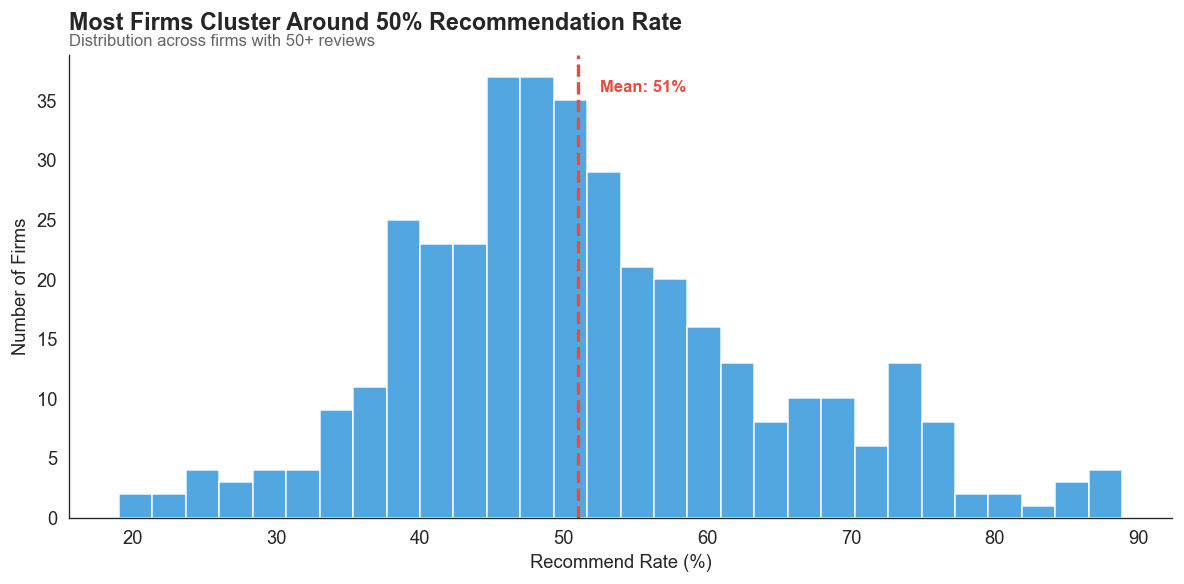

In [131]:
# --- Firm recommend rate distribution ---
# How much does recommend rate vary across firms? Informs encoding strategy.

fig, ax = plt.subplots(figsize=(10, 5))

recommend_binary = (df["recommend"] == "v").astype(int)
firm_stats = df.groupby("firm").agg(
    n_reviews=("recommend", "size"),
    recommend_rate=("recommend", lambda x: (x == "v").mean() * 100)
)
firm_reliable = firm_stats[firm_stats["n_reviews"] >= 50]
overall_mean = recommend_binary.mean() * 100

ax.hist(firm_reliable["recommend_rate"], bins=30, color="#3498db", edgecolor="white", alpha=0.85)

# Mean line with label
ax.axvline(overall_mean, color="#e74c3c", linestyle="--", linewidth=2)
ax.text(overall_mean + 1.5, ax.get_ylim()[1] * 0.92, f'Mean: {overall_mean:.0f}%', 
        fontsize=10, fontweight='bold', color='#e74c3c')

ax.set_xlabel("Recommend Rate (%)")  
ax.set_ylabel("Number of Firms")  

ax.set_title("Most Firms Cluster Around 50% Recommendation Rate", fontsize=14, loc='left', pad=15)  # fontweight from rcParams
ax.text(0, 1.02, "Distribution across firms with 50+ reviews", 
        transform=ax.transAxes, fontsize=10, color='#666666')

plt.tight_layout()
save_fig("eda_firm_recommend_rates")
plt.show()

Saved: eda_jobtitle_recommend_rates_v1.png


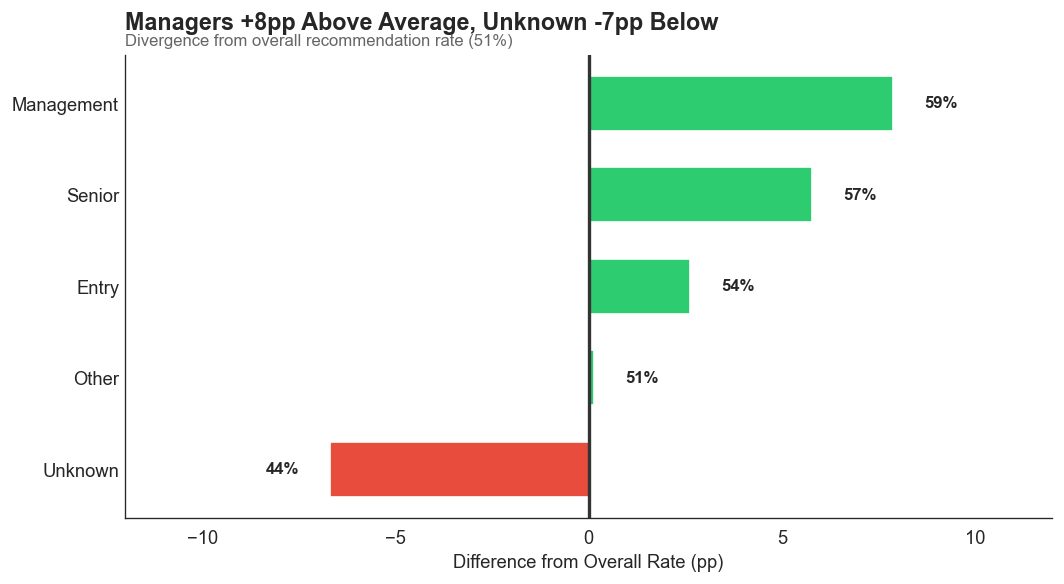

In [132]:
# --- Job title group recommend rates ---
# Does job title type (seniority / anonymity) correlate with recommendation?

titles = df["job_title"].fillna("")
titles_lower = titles.str.lower()
recommend_binary = (df["recommend"] == "v").astype(int)

# Seniority keyword matching (priority order)
SENIORITY_PATTERNS = [
    ("Management", r"\bexecutive\b|\bceo\b|\bcfo\b|\bcto\b|\bcoo\b|\bchief\b|\bpresident\b|\bvp\b|\bvice\s*president\b|\bdirector\b|\bmanager\b|\bmgr\b|\blead\b"),
    ("Senior", r"\bsenior\b|\bsr\.?\b"),
    ("Entry", r"\bassociate\b|\bjunior\b|\bjr\.?\b|\bintern\b"),
]

has_title = titles.str.strip() != ""
is_anon = titles_lower.str.contains("anonymous", na=False)

# Assign groups with priority
group = pd.Series("Other", index=df.index)
group[~has_title] = "Unknown"
group[has_title & is_anon] = "Unknown"

matched_any = pd.Series(False, index=df.index)
for label, pattern in SENIORITY_PATTERNS:
    mask = titles_lower.str.contains(pattern, regex=True, na=False) & ~matched_any
    group[mask] = label
    matched_any = matched_any | titles_lower.str.contains(pattern, regex=True, na=False)

# Compute rates
group_order = ["Management", "Senior", "Entry", "Other", "Unknown"]
rates = []
counts = []
for g in group_order:
    mask = group == g
    rates.append(recommend_binary[mask].mean() * 100)
    counts.append(mask.sum())

overall_rate = recommend_binary.mean() * 100

fig, ax = plt.subplots(figsize=(9, 5))

y_pos = np.arange(len(group_order))
divergence = [r - overall_rate for r in rates[::-1]]
colors = ["#2ecc71" if d > 0 else "#e74c3c" for d in divergence]

bars = ax.barh(y_pos, divergence, color=colors, height=0.6)

# Zero line (overall mean)
ax.axvline(0, color="#333333", linewidth=2)

# Value labels - always on the outside end of bars
for i, (div, rate) in enumerate(zip(divergence, rates[::-1])):
    if div > 0:
        ax.text(div + 0.8, i, f'{rate:.0f}%', va='center', ha='left', fontsize=10, fontweight='bold')
    else:
        ax.text(div - 0.8, i, f'{rate:.0f}%', va='center', ha='right', fontsize=10, fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(group_order[::-1]) 
ax.set_xlabel("Difference from Overall Rate (pp)") 
ax.set_xlim(-12, 12)
ax.tick_params(axis='y', length=0)

ax.set_title("Managers +8pp Above Average, Unknown -7pp Below", fontsize=14, loc='left', pad=15)  # fontweight from rcParams
ax.text(0, 1.02, f"Divergence from overall recommendation rate ({overall_rate:.0f}%)", 
        transform=ax.transAxes, fontsize=10, color='#666666')

plt.tight_layout()
save_fig("eda_jobtitle_recommend_rates")
plt.show()

Date range: 2008-01-31 to 2021-06-08
Span: 4,877 days

Reviews per year:
date_review
2008      5693
2009      5958
2010     10110
2011     10886
2012     20587
2013     24696
2014     39505
2015     69241
2016     84427
2017     91333
2018     87954
2019    103288
2020    140310
2021    144578
Name: count, dtype: int64
Saved: eda_reviews_per_year_v1.png


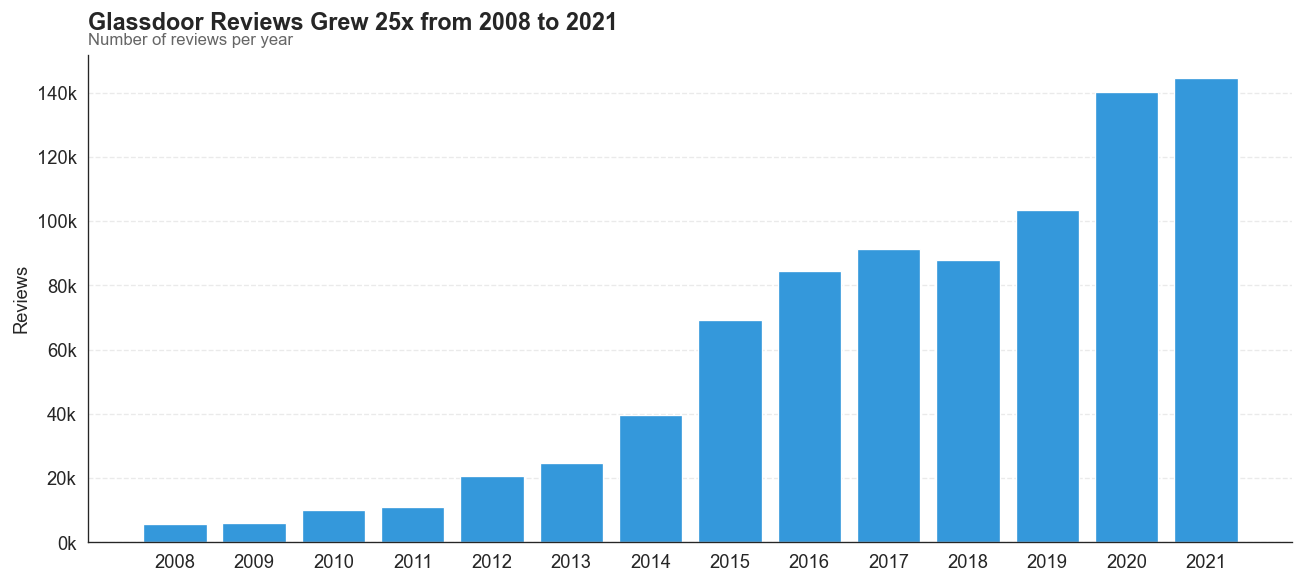

In [133]:
# Date range and temporal distribution
df["date_review"] = pd.to_datetime(df["date_review"])
print(f"Date range: {df['date_review'].min().date()} to {df['date_review'].max().date()}")
print(f"Span: {(df['date_review'].max() - df['date_review'].min()).days:,} days")

# Reviews per year
reviews_per_year = df["date_review"].dt.year.value_counts().sort_index()
print("\nReviews per year:")
print(reviews_per_year)

fig, ax = plt.subplots(figsize=(11, 5))

years = reviews_per_year.index
counts = reviews_per_year.values

ax.bar(years, counts, color='#3498db', edgecolor='white', linewidth=0.8, width=0.8)

ax.set_xlabel("")
ax.set_ylabel("Reviews")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x/1000:.0f}k'))
ax.set_xticks(years)
ax.set_ylim(0, None)
ax.yaxis.grid(True, linestyle='--', alpha=0.4)  # Helps compare across years
ax.set_axisbelow(True)  # Grid behind bars

ax.set_title("Glassdoor Reviews Grew 25x from 2008 to 2021", fontsize=14, loc='left', pad=15)
ax.text(0, 1.02, "Number of reviews per year", 
        transform=ax.transAxes, fontsize=10, color='#666666')

plt.tight_layout()
save_fig("eda_reviews_per_year")
plt.show()

Saved: eda_recommend_rate_by_year_v1.png


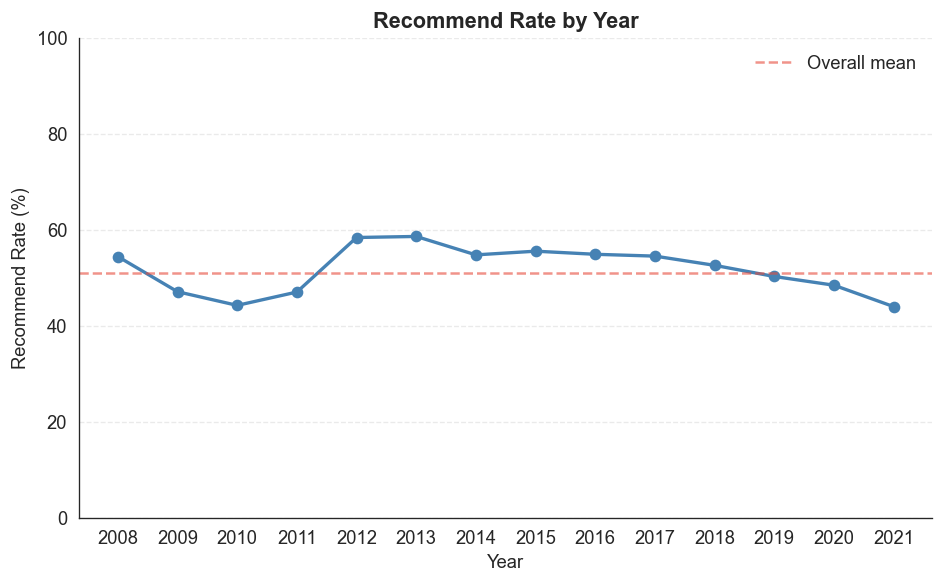

In [134]:
# Analyse recommend rate by year
df["review_year"] = pd.to_datetime(df["date_review"]).dt.year

year_stats = df.groupby("review_year").agg(
    n_reviews=("recommend", "count"),
    recommend_rate=("recommend", lambda x: (x == "v").mean() * 100)
).reset_index()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(year_stats["review_year"], year_stats["recommend_rate"], "o-", color="steelblue", linewidth=2)
ax.axhline(y=(df["recommend"] == "v").mean() * 100, color="#e74c3c", linestyle="--", alpha=0.6, label="Overall mean")
ax.set_xlabel("Year")
ax.set_ylabel("Recommend Rate (%)")
ax.set_ylim(0, 100)
ax.set_xticks(year_stats["review_year"])
ax.set_title("Recommend Rate by Year")
ax.legend(frameon=False)
ax.yaxis.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
save_fig("eda_recommend_rate_by_year")
plt.show()

Recommendation rates peaked at ~58% in 2012-2013 before declining steadily to ~44% by 2021; pre-2012 years may be excluded as sub-rating "Culture and Values" was introduced ~2012. This temporal variation suggests year should be retained as a feature.

In [135]:
# Location coverage
n_missing_loc = df["location"].isnull().sum()
print(f"Missing location: {n_missing_loc:,} ({n_missing_loc / len(df) * 100:.1f}%)")
print(f"Unique locations: {df['location'].nunique():,}")
print(f"\nTop 10 locations:")
print(df["location"].value_counts().head(10))

Missing location: 297,343 (35.5%)
Unique locations: 14,486

Top 10 locations:
location
London, England, England     58665
New York, NY                 31172
Bangalore                    28102
Hyderābād                    11458
Mumbai                        9543
Gurgaon, Haryana, Haryana     8562
Chicago, IL                   7840
Singapore                     7581
San Francisco, CA             7371
Dublin, Dublin                7364
Name: count, dtype: int64


**Takeaway — Metadata:**
- **Employee status:** 58.7% Current vs 41.3% Former. Current employees recommend more (56% Positive vs 44%), making `employee_status` a potentially useful binary feature. 
- **Firm:** 428 unique firms with heavy concentration (top 20 account for a large share). Per-firm recommend rates span a wide range, from below 25% to nearly 90%, roughly centered on the overall mean of 51%. This suggests using firm as feature. To tackle high cardinality consider target encoding.
- **Job title:** 62,275 unique titles with 9.4% empty and 19.4% "Anonymous Employee". Recommend rate differs by title type: Management/Senior (~66%), Entry (~61%), real unmatched titles (~60%), blank/anonymous (~50-54%). Seniority keywords capture ~31% of rows; the rest split into "Unknown" (no title revealed) and "Other" (real title, no seniority keyword).
- **Temporal coverage:** 2008–2021, with volume peaking in 2019–2021 (>100K reviews/year). Early years (2008–2011) have <11K reviews and are missing `culture_values` entirely. 
- **Yearly trends:** Recommend rate declines gradually from ~54% (2017) to ~44% (2021). The relationship does not appear strictly linear, suggesting one-hot encoding may be preferable to treating year as ordinal.
- **Location:** 35.5% missing, 14,486 unique values — unlikely to be useful without significant aggregation. Consider dropping.
- **Worth keeping:** `employee_status` (binary), `date_review` (for temporal features or filtering).


---
## 2.8 Summary: Data Quality Flags for data preparation

Key findings to carry forward into the next stage.

### EDA Summary — Data Quality Flags for Stage 3

### 1. Missing Values
- `diversity_inclusion`: 83.8% missing — **structural** (introduced ~2020, not available for earlier reviews). Likely **drop** or use only for subset analysis.
- `culture_values`: 0% before 2012 — also structural (introduced mid-dataset).
- `location`: 35.5% missing.
- Sub-ratings (5 core cols): ~17–23% missing each — rows with all missing will be dropped; rows with partial missing may need imputation.
- Text (`headline`/`pros`/`cons`): minimal missing (<0.3%).

### 2. Missingness Patterns
- **Target-dependent:** "No Opinion" reviews have ~55–61% missing sub-ratings vs ~3–9% for Positive/Negative — missingness is not random w.r.t. target.
- **Block missingness:** Sub-rating null indicators are correlated 0.9+ (excl. `diversity_inclusion`) — reviewers skip all optional sub-ratings together, not individual ones.
- 142K reviews (17%) have all 5 core sub-ratings missing; 88% of these are "No Opinion".
- Not status-dependent: Former employees ~2–3pp more missing (minor).
- **Class balance impact:** Filtering shifts the binary split from 51/49 to 60/40, primarily because "No Opinion" reviews disproportionately have missing sub-ratings. Stratified sampling preserves this balance across splits.

### 3. Duplicates
- 33,515 duplicate rows (4.0%) — likely drop.

### 4. Leakage Risk — Construct Overlap
- `overall_rating`: r = 0.47 with binary target — moderately correlated, distinct concept. **Keep with ablation test.**
- `ceo_approv`: 87% construct overlap — conceptually distinct from recommendation. **Keep with ablation test.**
- `outlook`: 92% construct overlap — near-synonymous with target. **Drop** (leakage risk).
- **Text Leakage:** Only 0.7% of reviews mention "recommend" — minimal risk.

### 5. Sub-Rating Target Correlations (Point-Biserial)
- `culture_values`: r = 0.55 (strongest)
- `senior_mgmt`: r = 0.53
- `career_opp`: r = 0.49
- `overall_rating`: r = 0.47
- `comp_benefits`: r = 0.41
- `diversity_inclusion`: r = 0.40 (but 83.8% missing)
- `work_life_balance`: r = 0.39

### 6. Short Reviews
- Reviews <5 words may not produce meaningful BERTopic clusters.
- Consider minimum word threshold in text preprocessing stage.

### 7. Employee Status
- Current employees recommend more (56% Positive vs 44% for Former).
- `employee_status` may be a useful feature.

### 8. Other Feature Notes
- `recommend` has 3 classes.
- Binary split: ~51% Positive vs ~49% Not Positive before filtering (near-balanced).
- Sub-ratings: all left-skewed (most ratings 3–5).
- Job title: very high cardinality (62K unique), 9.4% empty.

### 9. Temporal Scope
- Date range: 2008–2021, volume peaks 2019–2021.
- Consider filtering to 2012–2021 for relevance and feature consistency (`culture_values` only exists from 2012).